# DINO self-distillation

A student sees one view of a digit and predicts a distribution produced by a slowly moving teacher on another view.

The teacher uses a running centre and a lower softmax temperature. Its weights track the student by exponential moving average. This two-view convolutional exercise studies DINO's self-distillation objective with a small encoder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, f1_score


def digit_data():
    digits = load_digits()
    train, test = train_test_split(
        np.arange(len(digits.target)), test_size=0.25, stratify=digits.target, random_state=17
    )
    x = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
    return x[train], x[test], digits.target[train], digits.target[test]


def view(x):
    n = len(x)
    padded = F.pad(x, (1, 1, 1, 1))
    offset = torch.randint(3, (n, 2))
    row = offset[:, 0, None, None] + torch.arange(8)[None, :, None]
    col = offset[:, 1, None, None] + torch.arange(8)[None, None, :]
    moved = padded[torch.arange(n)[:, None, None], 0, row, col][:, None]
    return (moved + 0.06 * torch.randn_like(moved)).clamp(0, 1)


@torch.no_grad()
def embed(model, x):
    model.eval()
    return torch.cat([model(batch) for batch in x.split(96)]).flatten(1).numpy()


def compare(initial, trained, x, t, y, yt):
    systems = [
        ("Raw pixels", x.flatten(1).numpy(), t.flatten(1).numpy()),
        ("Random encoder", embed(initial, x), embed(initial, t)),
        ("Trained encoder", embed(trained, x), embed(trained, t)),
    ]
    rows = []
    for name, a, b in systems:
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1200, C=1))
        probe.fit(a, y)
        guess = probe.predict(b)
        power = np.linalg.svd(b - b.mean(0), compute_uv=False) ** 2
        p = power[power > 0] / max(power.sum(), 1e-30)
        rank = float(np.exp(-(p * np.log(p)).sum())) if len(p) else 0.0
        rows.append(
            (
                name,
                float((guess == yt).mean()),
                balanced_accuracy_score(yt, guess),
                f1_score(yt, guess, average="macro"),
                rank,
            )
        )
    report(["Features", "Test accuracy", "Balanced accuracy", "Macro F1", "Effective rank"], rows)


def conv_encoder():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1),
        nn.GELU(),
        nn.AvgPool2d(2),
        nn.Conv2d(16, 24, 3, padding=1),
        nn.GELU(),
        nn.Flatten(),
        nn.Linear(24 * 4 * 4, 32),
    )


class Distiller(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = conv_encoder()
        self.project = nn.Sequential(nn.Linear(32, 48), nn.GELU(), nn.Linear(48, 24))
        self.prototypes = nn.Parameter(torch.randn(16, 24) * 0.1)

    def forward(self, x):
        feat = F.normalize(self.project(self.backbone(x)), dim=1)
        return F.linear(feat, F.normalize(self.prototypes, dim=1))


@torch.no_grad()
def moving_average(teacher, student, m):
    for target, online in zip(teacher.parameters(), student.parameters()):
        target.lerp_(online, 1 - m)

## Train across independently augmented views

Each teacher output supervises the other student view. Centre updates use uncentred teacher logits after computing the current loss.

In [2]:
seed()
x, t, y, yt = digit_data()
student = Distiller()
initial = copy.deepcopy(student.backbone)
teacher = copy.deepcopy(student).eval().requires_grad_(False)
opt = torch.optim.AdamW(student.parameters(), lr=0.0015)
centre = torch.zeros(1, 16)
curve = []
for epoch in range(22):
    losses = []
    for ids in torch.randperm(len(x)).split(80):
        u, v = view(x[ids]), view(x[ids])
        su, sv = student(u), student(v)
        with torch.no_grad():
            tu, tv = teacher(u), teacher(v)
            pu = ((tu - centre) / 0.05).softmax(1)
            pv = ((tv - centre) / 0.05).softmax(1)
        loss = -0.5 * (
            (pu * F.log_softmax(sv / 0.12, dim=1)).sum(1).mean()
            + (pv * F.log_softmax(su / 0.12, dim=1)).sum(1).mean()
        )
        opt.zero_grad()
        loss.backward()
        opt.step()
        moving_average(teacher, student, 0.985)
        centre.lerp_(torch.cat((tu, tv)).mean(0, keepdim=True), 0.10)
        losses.append(loss.item())
    curve.append(np.mean(losses))

## Measure representation and prototype use

Class labels fit the linear probe. The entropy diagnostics use no labels and distinguish uncertain predictions from a prototype shared by every image.

,Features,Test accuracy,Balanced accuracy,Macro F1,Effective rank
0,Raw pixels,0.97111,0.97084,0.97099,20.17443
1,Random encoder,0.96667,0.96650,0.96657,10.29035
2,Trained encoder,0.94000,0.93962,0.93982,1.82608


,Mean sample entropy (nats),Marginal entropy (nats),Effective prototypes,Uniform entropy
0,2.72411,2.77054,15.96722,2.77259


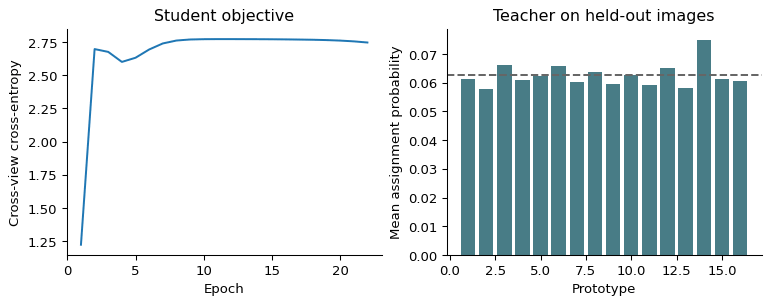

In [3]:
compare(initial, teacher.backbone, x, t, y, yt)
with torch.no_grad():
    p = ((teacher(t) - centre) / 0.05).softmax(1)
    mass = p.mean(0)
    entropy = -(p * p.clamp_min(1e-12).log()).sum(1).mean().item()
    marginal = -(mass * mass.clamp_min(1e-12).log()).sum().item()
report(
    [
        "Mean sample entropy (nats)",
        "Marginal entropy (nats)",
        "Effective prototypes",
        "Uniform entropy",
    ],
    [(entropy, marginal, np.exp(marginal), np.log(p.shape[1]))],
)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), layout="constrained")
axes[0].plot(range(1, len(curve) + 1), curve)
axes[0].set(xlabel="Epoch", ylabel="Cross-view cross-entropy", title="Student objective")
axes[1].bar(range(1, 17), mass.numpy(), color="#487c86")
axes[1].axhline(1 / 16, ls="--", color="0.4")
axes[1].set(
    xlabel="Prototype", ylabel="Mean assignment probability", title="Teacher on held-out images"
)
plt.show()

## Interpreting the result

The teacher used almost all 16 prototypes in aggregate, yet its mean per-image entropy was 2.724 nats, close to the uniform value of 2.773. Its individual predictions were diffuse. The trained backbone also had lower effective rank and probe accuracy than its frozen random baseline.

The frozen probe measures class information in the backbone before the projection head.

## Exercise

Increase the teacher temperature towards the student temperature, then inspect the sample and marginal entropies together.

## References

[Caron et al. (2021), Emerging Properties in Self-Supervised Vision Transformers](https://arxiv.org/abs/2104.14294)

[Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)